In [ ]:
from itertools import product
from fractions import Fraction

S = list(product(range(1, 7), repeat=2))
A = [s for s in S if sum(s) == 8]
P = Fraction(len(A), len(S))
print("n(S) =", len(S), "| n(A) =", len(A))
print("P(A) =", P, "=", round(float(P), 4))


n(S) = 36 | n(A) = 5
P(A) = 5/36 = 0.1389


In [ ]:
import math

pin = math.perm(10, 4)
print("Jumlah PIN unik :", pin)
print("P(tebakan benar):", round(1 / pin, 6))

total = math.comb(8, 3)
favorable = math.comb(3, 2) * math.comb(5, 1)
print("Total tim       :", total)
print("Tim 2 jago + 1  :", favorable)
print("P(tim tsb)      :", round(favorable / total, 4))


Jumlah PIN unik : 5040
P(tebakan benar): 0.000198
Total tim       : 56
Tim 2 jago + 1  : 15
P(tim tsb)      : 0.2679


In [ ]:
n = 100
P_py, P_java, P_both = 60 / n, 40 / n, 25 / n
P_union = P_py + P_java - P_both
print("P(Python U Java)    =", round(P_union, 2))
print("P(tidak keduanya)   =", round(1 - P_union, 2))


P(Python U Java)    = 0.75
P(tidak keduanya)   = 0.25


         Berhasil  Gagal
WiFi          180     20
Seluler       160     40 

P(A | W)  = 0.9
P(A | JS) = 0.8

Cek independensi (WiFi):
P(A) x P(W) = 0.425
P(A n W)    = 0.45
Independen? False


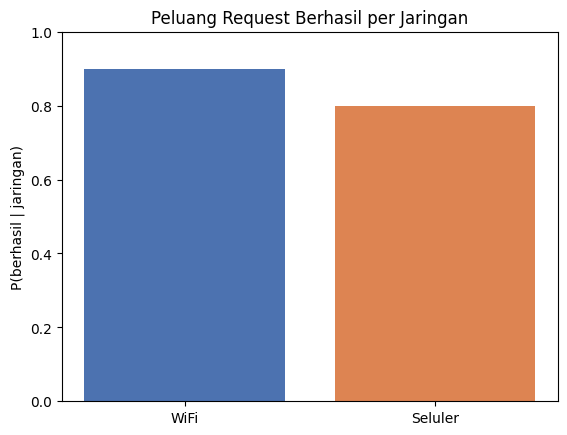

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.DataFrame({"Berhasil": [180, 160], "Gagal": [20, 40]},
                    index=["WiFi", "Seluler"])
print(data, "\n")

total = data.values.sum()
P_W  = data.loc["WiFi"].sum() / total
P_JS = data.loc["Seluler"].sum() / total
P_A  = data["Berhasil"].sum() / total
P_A_W  = data.loc["WiFi", "Berhasil"] / total
P_A_JS = data.loc["Seluler", "Berhasil"] / total

print("P(A | W)  =", round(P_A_W / P_W, 4))
print("P(A | JS) =", round(P_A_JS / P_JS, 4))
print("\nCek independensi (WiFi):")
print("P(A) x P(W) =", round(P_A * P_W, 4))
print("P(A n W)    =", round(P_A_W, 4))
print("Independen?", abs(P_A * P_W - P_A_W) < 1e-9)

plt.bar(["WiFi", "Seluler"], [P_A_W / P_W, P_A_JS / P_JS], color=["#4C72B0", "#DD8452"])
plt.ylim(0, 1); plt.ylabel("P(berhasil | jaringan)")
plt.title("Peluang Request Berhasil per Jaringan")
plt.show()

P(error) = 0.017
P(Server A | error) = 0.2941
P(Server B | error) = 0.3529
P(Server C | error) = 0.3529


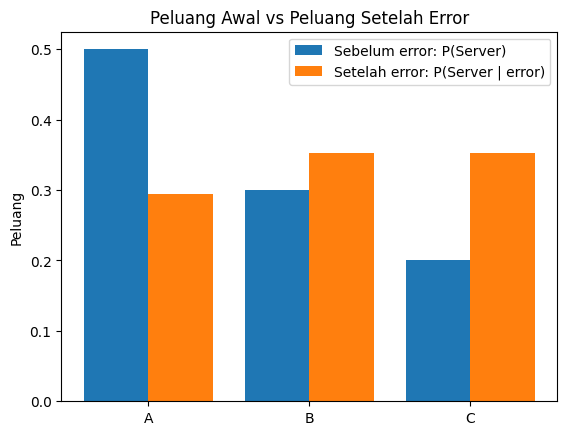

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

prior = {"A": 0.5, "B": 0.3, "C": 0.2}
err   = {"A": 0.01, "B": 0.02, "C": 0.03}

P_err = sum(prior[s] * err[s] for s in prior)
print("P(error) =", round(P_err, 4))

post = {s: prior[s] * err[s] / P_err for s in prior}
for s in prior:
    print(f"P(Server {s} | error) = {post[s]:.4f}")

x = np.arange(len(prior))
plt.bar(x - 0.2, list(prior.values()), width=0.4, label="Sebelum error: P(Server)")
plt.bar(x + 0.2, list(post.values()), width=0.4, label="Setelah error: P(Server | error)")
plt.xticks(x, list(prior.keys()))
plt.ylabel("Peluang"); plt.title("Peluang Awal vs Peluang Setelah Error")
plt.legend()
plt.show()

In [5]:
from fractions  import Fraction

P_spam      = Fraction(3, 10)
P_kata_spam = Fraction(6, 10)
P_kata_ok   = Fraction(5, 100)

P_kata = P_kata_spam * P_spam + P_kata_ok * (1 - P_spam)
P_spam_kata = P_kata_spam * P_spam / P_kata

print("P(kata 'gratis')   =", P_kata, "=", float(P_kata))
print("P(spam | 'gratis') =", P_spam_kata, "=", round(float(P_spam_kata), 4))

P(kata 'gratis')   = 43/200 = 0.215
P(spam | 'gratis') = 36/43 = 0.8372


Teori     : 0.1389
Simulasi  : 0.1368
Selisih   : 0.002


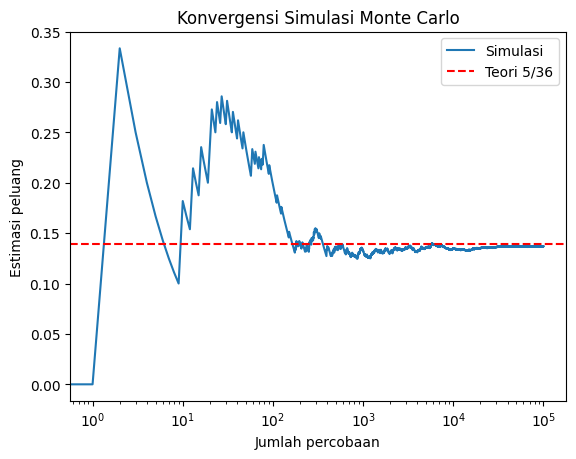

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
N = 100_000
d1 = rng.integers(1, 7, N)
d2 = rng.integers(1, 7, N)
hit = (d1 + d2 == 8)

print("Teori     :", round(5 / 36, 4))
print("Simulasi  :", round(hit.mean(), 4))
print("Selisih   :", round(abs(hit.mean() - 5 / 36), 4))

cum = np.cumsum(hit) / np.arange(1, N + 1)
plt.plot(cum, label="Simulasi")
plt.axhline(5 / 36, color="red", linestyle="--", label="Teori 5/36")
plt.xscale("log")
plt.xlabel("Jumlah percobaan"); plt.ylabel("Estimasi peluang")
plt.title("Konvergensi Simulasi Monte Carlo"); plt.legend()

Teori (n=23): 0.5073
Simulasi    : 0.509


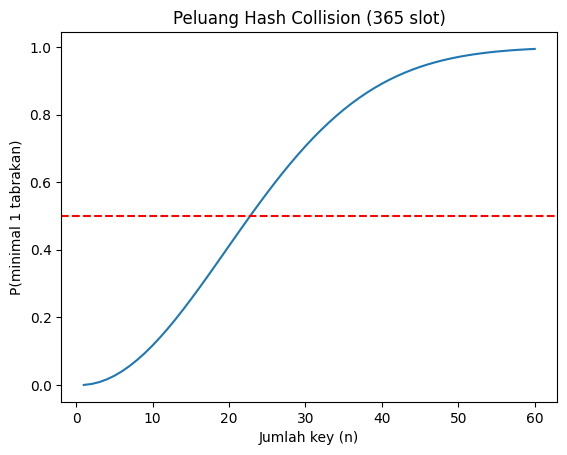

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def p_collision(n, m=365):
    p_unique = 1.0
    for i in range(n):
        p_unique *= (m - i) / m
    return 1 - p_unique

print("Teori (n=23):", round(p_collision(23), 4))

rng = np.random.default_rng(42)
trials = 20_000
count = sum(len(set(rng.integers(0, 365, 23))) < 23 for _ in range(trials))
print("Simulasi    :", round(count / trials, 4))

n_vals = np.arange(1, 61)
plt.plot(n_vals, [p_collision(n) for n in n_vals])
plt.axhline(0.5, color="red", linestyle="--")
plt.xlabel("Jumlah key (n)"); plt.ylabel("P(minimal 1 tabrakan)")
plt.title("Peluang Hash Collision (365 slot)")
plt.show()

P(X = 9) = 0.3874
P(X >= 8) = 0.9298
E(X) = 9.0
Var(X) = 0.9
Simulasi mean = 8.9984 | var = 0.8991


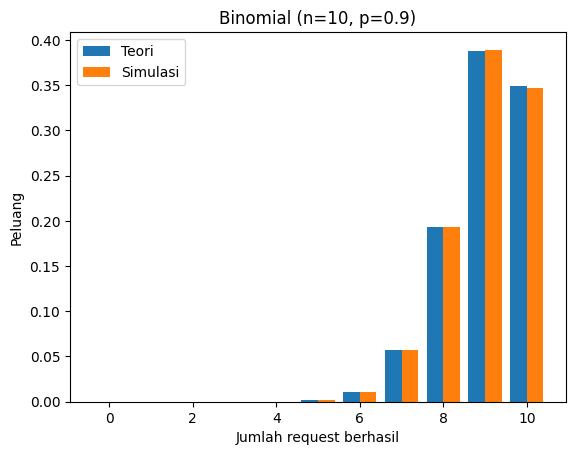

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
n, p = 10, 0.9
print("P(X = 9) =", round(binom.pmf(9, n, p), 4))
print("P(X >= 8) =", round(binom.sf(7, n, p), 4))
print("E(X) =", binom.mean(n, p))
print("Var(X) =", round(binom.var(n, p), 4))
rng = np.random.default_rng(42)
sim = rng.binomial(n, p, 100_000)
print("Simulasi mean =", round(sim.mean(), 4), "| var =", round(sim.var(), 4))
k = np.arange(0, n + 1)
plt.bar(k - 0.2, binom.pmf(k, n, p), width=0.4, label="Teori")
plt.bar(k + 0.2, np.bincount(sim, minlength=n + 1) / len(sim), width=0.4, label="Simulasi")
plt.xlabel("Jumlah request berhasil"); plt.ylabel("Peluang")
plt.title("Binomial (n=10, p=0.9)"); plt.legend()
plt.show()

P(X = 7) = 0.1044
P(X > 8) = 0.0681
E(X) = 5.0 | Var(X) = 5.0


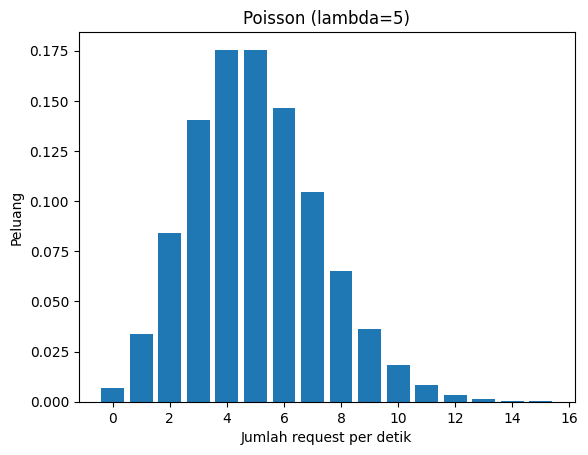

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson
lam = 5
print("P(X = 7) =", round(poisson.pmf(7, lam), 4))
print("P(X > 8) =", round(poisson.sf(8, lam), 4))
print("E(X) =", poisson.mean(lam), "| Var(X) =", poisson.var(lam))
k = np.arange(0, 16)
plt.bar(k, poisson.pmf(k, lam))
plt.xlabel("Jumlah request per detik"); plt.ylabel("Peluang")
plt.title("Poisson (lambda=5)")
plt.show()

P(X = 3) = 0.128
P(X <= 5) = 0.6723
E(X) = 5.0
Var(X) = 20.0


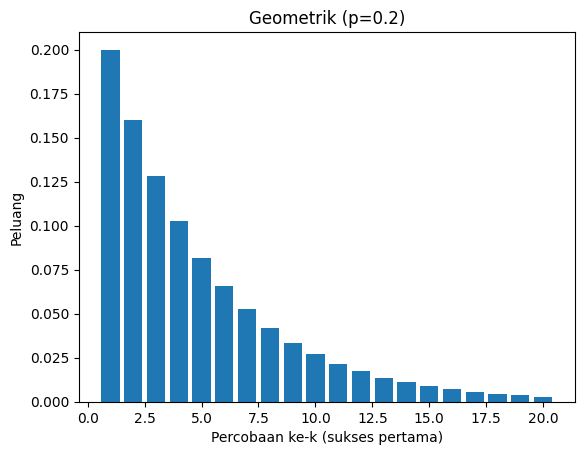

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import geom
p = 0.2
print("P(X = 3) =", round(geom.pmf(3, p), 4))
print("P(X <= 5) =", round(geom.cdf(5, p), 4))
print("E(X) =", geom.mean(p))
print("Var(X) =", geom.var(p))
k = np.arange(1, 21)
plt.bar(k, geom.pmf(k, p))
plt.xlabel("Percobaan ke-k (sukses pertama)"); plt.ylabel("Peluang")
plt.title("Geometrik (p=0.2)")
plt.show()

In [ ]:
import math
from scipy.stats import hypergeom
M, n, N = 20, 5, 4
print("P(X = 1) =", round(hypergeom.pmf(1, M, n, N), 4))
print("P(X >= 1) =", round(hypergeom.sf(0, M, n, N), 4))
print("E(X) =", hypergeom.mean(M, n, N))
manual = math.comb(5, 1) * math.comb(15, 3) / math.comb(20, 4)
print("Cek manual P(X = 1) =", round(manual, 4))

P(X = 1) = 0.4696
P(X >= 1) = 0.7183
E(X) = 1.0
Cek manual P(X = 1) = 0.4696


Total peluang = 1.0
E(X) = 1.0
E(X^2) = 2.0
Var(X) = 1.0
Std = 1.0


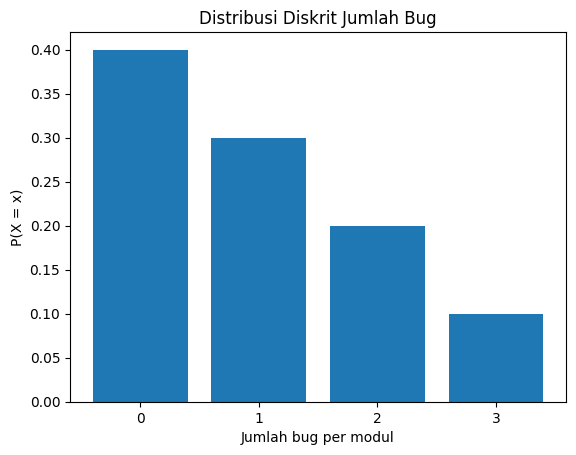

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
x = np.array([0, 1, 2, 3])
p = np.array([0.4, 0.3, 0.2, 0.1])
print("Total peluang =", round(p.sum(), 2))
E = np.sum(x * p)
E2 = np.sum(x**2 * p)
Var = E2 - E**2
print("E(X) =", E)
print("E(X^2) =", E2)
print("Var(X) =", Var)
print("Std =", round(np.sqrt(Var), 4))
plt.bar(x, p)
plt.xticks(x)
plt.xlabel("Jumlah bug per modul"); plt.ylabel("P(X = x)")
plt.title("Distribusi Diskrit Jumlah Bug")
plt.show()

P(X < 4) = 0.4
P(3 < X < 7) = 0.4
E(X) = 5.0 | Var(X) = 8.3333


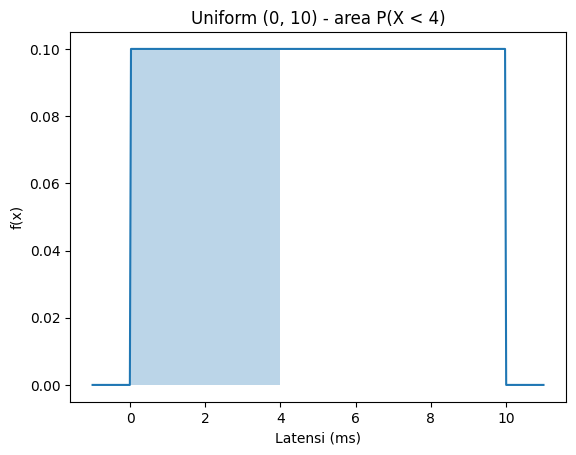

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import uniform
a, b = 0, 10
d = uniform(loc=a, scale=b - a)
print("P(X < 4) =", round(d.cdf(4), 4))
print("P(3 < X < 7) =", round(d.cdf(7) - d.cdf(3), 4))
print("E(X) =", d.mean(), "| Var(X) =", round(d.var(), 4))
x = np.linspace(-1, 11, 400)
plt.plot(x, d.pdf(x))
plt.fill_between(x, d.pdf(x), where=(x >= 0) & (x <= 4), alpha=0.3)
plt.xlabel("Latensi (ms)"); plt.ylabel("f(x)")
plt.title("Uniform (0, 10) - area P(X < 4)")
plt.show()

P(X <= 1) = 0.3935
P(X > 3) = 0.2231
E(X) = 2.0 | Var(X) = 4.0


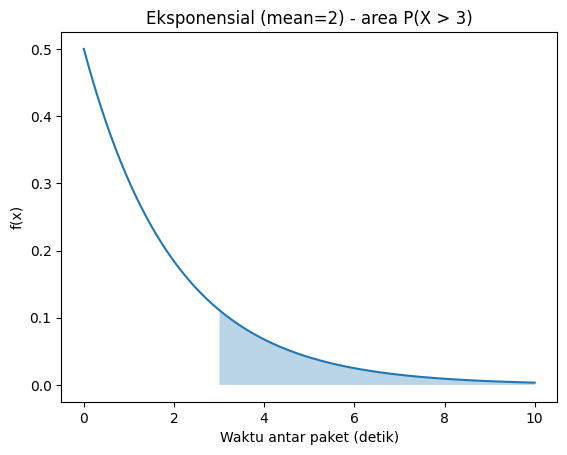

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import expon
mean_t = 2
d = expon(scale=mean_t)
print("P(X <= 1) =", round(d.cdf(1), 4))
print("P(X > 3) =", round(d.sf(3), 4))
print("E(X) =", d.mean(), "| Var(X) =", d.var())
x = np.linspace(0, 10, 400)
plt.plot(x, d.pdf(x))
plt.fill_between(x, d.pdf(x), where=(x >= 3), alpha=0.3)
plt.xlabel("Waktu antar paket (detik)"); plt.ylabel("f(x)")
plt.title("Eksponensial (mean=2) - area P(X > 3)")
plt.show()


P(X > 250) = 0.0478
P(170 < X < 230) = 0.6827
Persentil ke-95 = 249.35


Text(0.5, 1.0, 'Normal (mu=200, sigma=30) - area P(X > 250)')

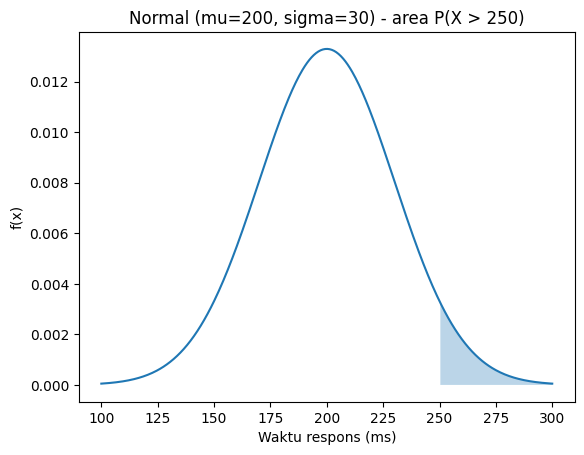

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
mu, sigma = 200, 30
d = norm(mu, sigma)
print("P(X > 250) =", round(d.sf(250), 4))
print("P(170 < X < 230) =", round(d.cdf(230) - d.cdf(170), 4))
print("Persentil ke-95 =", round(d.ppf(0.95), 2))
x = np.linspace(100, 300, 400)
plt.plot(x, d.pdf(x))
plt.fill_between(x, d.pdf(x), where=(x >= 250), alpha=0.3)
plt.xlabel("Waktu respons (ms)"); plt.ylabel("f(x)")
plt.title("Normal (mu=200, sigma=30) - area P(X > 250)")